<a href="https://colab.research.google.com/github/abdabdelli172-collab/TP1_MODELE_DIABETE/blob/main/TP1_Modele_Diabete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving pima-indians-diabetes.csv to pima-indians-diabetes.csv


In [4]:
from google.colab import files
uploaded = files.upload()

Saving pima-indians-diabetes.csv to pima-indians-diabetes.csv


In [6]:
import pandas as pd

df = pd.read_csv("pima-indians-diabetes.csv", header=None)

df.columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

print(df["Outcome"].value_counts())


Outcome
0    500
1    268
Name: count, dtype: int64


In [8]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if 'pima' in file.lower() or 'diabetes' in file.lower():
            print(os.path.join(root, file))

/content/pima-indians-diabetes.csv


In [9]:
import pandas as pd

columns = [
    'Pregnancies', 'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI',
    'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(
    '/content/pima-indians-diabetes.csv',
    header=None,
    names=columns
)

print(df.head())
print("\nDimensions:", df.shape)



   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dimensions: (768, 9)


In [10]:
print("Nombre de chaque classe :")
print(df['Outcome'].value_counts())

print("\nPourcentage de chaque classe :")
print(df['Outcome'].value_counts(normalize=True) * 100)


Nombre de chaque classe :
Outcome
0    500
1    268
Name: count, dtype: int64

Pourcentage de chaque classe :
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [11]:
from collections import Counter

print("Dimensions des données :")

print("X_train :", X_train.shape)
print("X_validation :", X_val.shape)
print("X_test :", X_test.shape)

print("\nRépartition des classes dans Training :")
print(Counter(y_train))

print("\nRépartition des classes dans Validation :")
print(Counter(y_val))

print("\nRépartition des classes dans Testing :")
print(Counter(y_test))



Dimensions des données :


NameError: name 'X_train' is not defined

In [12]:
from sklearn.model_selection import train_test_split

# Séparation des caractéristiques et de la cible
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Division : 70% entraînement, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("X_train :", X_train.shape)
print("X_validation :", X_val.shape)
print("X_test :", X_test.shape)



X_train : (537, 8)
X_validation : (115, 8)
X_test : (116, 8)


In [13]:
from collections import Counter

print("Training :", Counter(y_train))
print("Validation :", Counter(y_val))
print("Testing :", Counter(y_test))


Training : Counter({0: 350, 1: 187})
Validation : Counter({0: 75, 1: 40})
Testing : Counter({0: 75, 1: 41})


In [14]:
!pip install imbalanced-learn

import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from collections import Counter

# 1. Remplacer les zéros invalides par NaN
colonnes_zero = [
    'Glucose', 'BloodPressure',
    'SkinThickness', 'Insulin', 'BMI'
]

X_train_clean = X_train.copy()
X_val_clean = X_val.copy()
X_test_clean = X_test.copy()

for col in colonnes_zero:
    X_train_clean[col] = X_train_clean[col].replace(0, np.nan)
    X_val_clean[col] = X_val_clean[col].replace(0, np.nan)
    X_test_clean[col] = X_test_clean[col].replace(0, np.nan)

# 2. Imputation par la médiane
imputer = SimpleImputer(strategy='median')

X_train_imp = imputer.fit_transform(X_train_clean)
X_val_imp = imputer.transform(X_val_clean)
X_test_imp = imputer.transform(X_test_clean)

# 3. Normalisation
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

# 4. Équilibrage avec SMOTE
smote = SMOTE(
    sampling_strategy={0: 1000, 1: 1000},
    random_state=42,
    k_neighbors=5
)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

# 5. Vérification
print("Avant SMOTE :", Counter(y_train))
print("Après SMOTE :", Counter(y_train_balanced))
print("Dimensions finales :", X_train_balanced.shape)



Avant SMOTE : Counter({0: 350, 1: 187})
Après SMOTE : Counter({1: 1000, 0: 1000})
Dimensions finales : (2000, 8)


In [16]:
import numpy as np

In [17]:
print("Avant SMOTE :", Counter(y_train))
print("Après SMOTE :", Counter(y_train_balanced))
print("Dimensions finales :", X_train_balanced.shape)

Avant SMOTE : Counter({0: 350, 1: 187})
Après SMOTE : Counter({1: 1000, 0: 1000})
Dimensions finales : (2000, 8)


In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproductibilité
tf.keras.utils.set_random_seed(42)

# Construction du modèle ANN
model = Sequential([
    Dense(32, activation='relu', input_shape=(8,)),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Compilation
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Arrêt anticipé
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Entraînement
history = model.fit(
    X_train_balanced,
    y_train_balanced,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.6725 - loss: 0.6512 - val_accuracy: 0.6957 - val_loss: 0.6241
Epoch 2/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7235 - loss: 0.5724 - val_accuracy: 0.7130 - val_loss: 0.5758
Epoch 3/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7520 - loss: 0.5084 - val_accuracy: 0.7391 - val_loss: 0.5677
Epoch 4/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7575 - loss: 0.4943 - val_accuracy: 0.7130 - val_loss: 0.5703
Epoch 5/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7620 - loss: 0.4851 - val_accuracy: 0.7217 - val_loss: 0.5653
Epoch 6/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7815 - loss: 0.4714 - val_accuracy: 0.7304 - val_loss: 0.5707
Epoch 7/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7810 - loss: 0.4631 - val_accuracy: 0.7217 - val_loss: 0.5763
Epoch 8/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7865 - loss: 0.4557 - val_accuracy: 0.7

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Prédiction
y_pred_prob = model.predict(X_test_scaled)

# Conversion en classes 0 et 1
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

# Calcul des métriques
print("===== ÉVALUATION DU MODÈLE ANN =====")

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision :", precision_score(y_test, y_pred))
print("Recall :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))

print("\nClassification Report :")
print(classification_report(y_test, y_pred))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred))



4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
===== ÉVALUATION DU MODÈLE ANN =====
Accuracy : 0.8103448275862069
Precision : 0.7317073170731707
Recall : 0.7317073170731707
F1-score : 0.7317073170731707

Classification Report :
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        75
           1       0.73      0.73      0.73        41

    accuracy                           0.81       116
   macro avg       0.79      0.79      0.79       116
weighted avg       0.81      0.81      0.81       116


Matrice de confusion :
[[64 11]
 [11 30]]


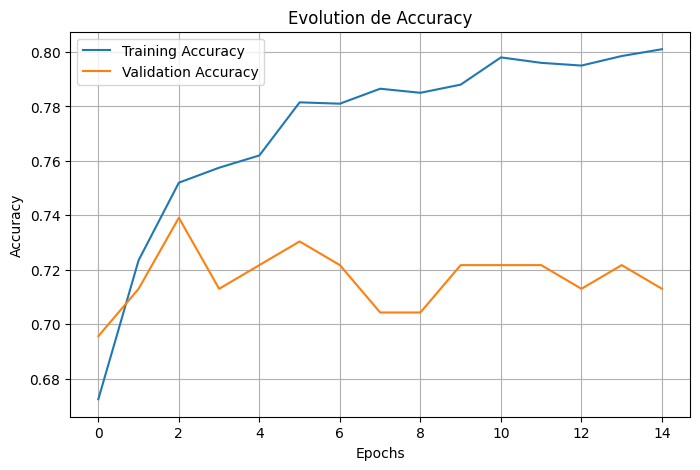

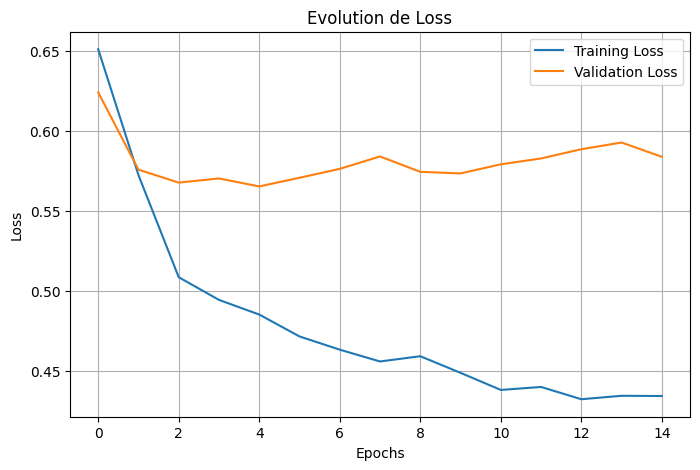

In [20]:
import matplotlib.pyplot as plt

# Courbe Accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Evolution de Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# Courbe Loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Evolution de Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()



In [21]:
# Sauvegarde du modèle ANN
model.save('/content/diacare_ann.keras')

print("Modèle sauvegardé avec succès !")

Modèle sauvegardé avec succès !


In [22]:
import joblib

joblib.dump(imputer, '/content/diacare_imputer.pkl')
joblib.dump(scaler, '/content/diacare_scaler.pkl')

print("Prétraitement sauvegardé avec succès !")



Prétraitement sauvegardé avec succès !


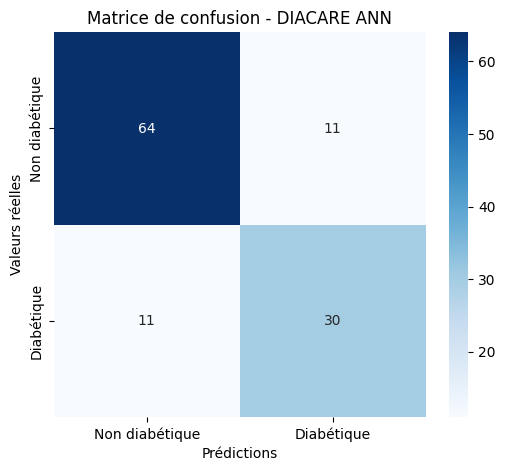

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non diabétique', 'Diabétique'],
    yticklabels=['Non diabétique', 'Diabétique']
)

plt.title('Matrice de confusion - DIACARE ANN')
plt.xlabel('Prédictions')
plt.ylabel('Valeurs réelles')
plt.show()



In [25]:
import joblib
import os

# Création du dossier
os.makedirs('/content/DIACARE', exist_ok=True)

# Sauvegarde du modèle
model.save('/content/DIACARE/diacare_ann.keras')

# Sauvegarde des outils de prétraitement
joblib.dump(imputer, '/content/DIACARE/imputer.pkl')
joblib.dump(scaler, '/content/DIACARE/scaler.pkl')

print("Tous les fichiers sont sauvegardés !")



Tous les fichiers sont sauvegardés !


In [26]:
from google.colab import files

files.download('/content/DIACARE/diacare_ann.keras')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
files.download('/content/DIACARE/imputer.pkl')
files.download('/content/DIACARE/scaler.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# New Section

In [28]:
!zip -r /content/DIACARE.zip /content/DIACARE

  adding: content/DIACARE/ (stored 0%)
  adding: content/DIACARE/imputer.pkl (deflated 36%)
  adding: content/DIACARE/scaler.pkl (deflated 22%)
  adding: content/DIACARE/diacare_ann.keras (deflated 69%)


In [29]:
from google.colab import files
files.download('/content/DIACARE.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(df["Outcome"].value_counts())

NameError: name 'df' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("diabetes.csv")

print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'diabetes.csv'

In [ ]:
import os

print(os.listdir())

['.config', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv("pima-indians-diabetes.csv", header=None)

print(df.shape)
df.head()

(768, 9)


,0,1,2,3,4,5,6,7,8
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print("Dimensions :", df.shape)

# عرض أسماء الأعمدة
print("Colonnes :", df.columns.tolist())

# عرض أول 5 أسطر
display(df.head())

# معرفة عدد الحالات في كل فئة
print(df[8].value_counts())


Dimensions : (768, 9)
Colonnes : [0, 1, 2, 3, 4, 5, 6, 7, 8]


,0,1,2,3,4,5,6,7,8
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


8
0    500
1    268
Name: count, dtype: int64


In [ ]:
df.columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

display(df.head())


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
colonnes_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in colonnes_zero:
    print(col, ":", (df[col] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [ ]:
mport numpy as np
from sklearn.impute import SimpleImputer

# تحويل الأصفار إلى قيم مفقودة
df[["Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"]] = df[["Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI"]].replace(0, np.nan)

# تعويض القيم المفقودة بالوسيط
imputer = SimpleImputer(strategy="median")

df[["Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"]] = imputer.fit_transform(
    df[["Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI"]]
)

# التحقق من القيم المفقودة
print(df.isnull().sum())



SyntaxError: invalid syntax (1723423271.py, line 1)

In [ ]:
mport numpy as np
from sklearn.impute import SimpleImputer

colonnes = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[colonnes] = df[colonnes].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")

df[colonnes] = imputer.fit_transform(df[colonnes])

print(df.isnull().sum())

SyntaxError: invalid syntax (861252926.py, line 1)

In [ ]:
import numpy as np
from sklearn.impute import SimpleImputer

colonnes = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[colonnes] = df[colonnes].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")

df[colonnes] = imputer.fit_transform(df[colonnes])

print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (537, 8)
Validation: (115, 8)
Testing: (116, 8)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Création du modèle
model = LogisticRegression(max_iter=1000)

# Entraînement
model.fit(X_train, y_train)

print("Le modèle est entraîné avec succès !")


Le modèle est entraîné avec succès !


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Prédiction
y_pred = model.predict(X_val)

# Calcul des métriques
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)


Accuracy: 0.7130434782608696
Precision: 0.5945945945945946
Recall: 0.55
F1-score: 0.5714285714285714


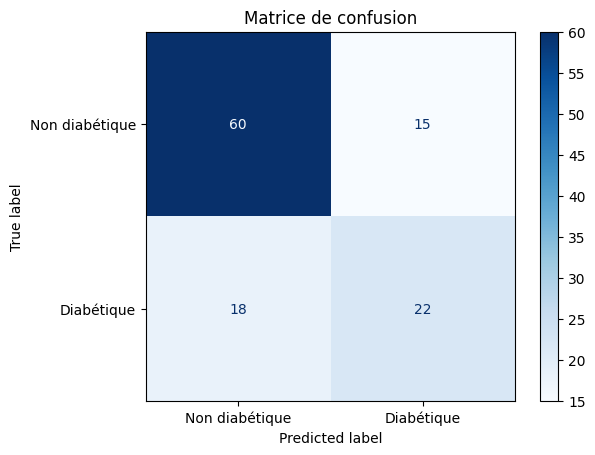

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non diabétique", "Diabétique"]
)

disp.plot(cmap="Blues")
plt.title("Matrice de confusion")
plt.show()


In [ ]:
print(cm)

[[60 15]
 [18 22]]


In [ ]:
from sklearn.metrics import classification_report

y_test_pred = model.predict(X_test)

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.78      0.92      0.84        75
           1       0.78      0.51      0.62        41

    accuracy                           0.78       116
   macro avg       0.78      0.72      0.73       116
weighted avg       0.78      0.78      0.76       116



In [ ]:
import time

start = time.time()

model.predict(X_test)

end = time.time()

print("Temps de prédiction:", end - start, "secondes")

Temps de prédiction: 0.005696773529052734 secondes


In [ ]:
Temps de prédiction: 0.005696773529052734 secondes

SyntaxError: invalid syntax (3147029874.py, line 1)

In [ ]:
import joblib

joblib.dump(model, "diacare_model.pkl")

print("Modèle sauvegardé avec succès !")

Modèle sauvegardé avec succès !


In [ ]:
import joblib

joblib.dump(model, "diacare_model.pkl")

print("Modèle sauvegardé avec succès !")

Modèle sauvegardé avec succès !
